# NGSIM I-80: Unsupervised Clustering and Anomaly Detection (Milestone 2)
Run every cell from top to bottom (Kernel > Restart & Run All).
Only change `CSV_PATH` below if your file is somewhere else.
Units in the NGSIM file: speed = ft/s, acceleration = ft/s^2, space headway = ft, time headway = s.

In [3]:
# Cell 1: settings, load data, clean types
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

CSV_PATH = "NGSIM_Data.csv"     
SEED = 42
FLAG_RATE = 0.02                 
MIN_FRAMES = 100                 
MAINLINE_LANES = [1, 2, 3, 4, 5, 6]  
N_SAMPLE = 100_000
FEATURES = ["v_Vel", "v_Acc", "Space_Headway"]
FT_S_TO_MPH = 0.681818
CLIP_ACC = 11.19                 # NGSIM acceleration values are capped at +/-11.2 ft/s^2

os.makedirs("figures", exist_ok=True)
REPORT = {}                      # numbers collected for the report


def to_num(s):
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")


cols = ["Vehicle_ID", "v_Class", "v_Vel", "v_Acc", "Lane_ID", "Space_Headway", "Time_Headway"]
df = pd.read_csv(CSV_PATH, usecols=cols, low_memory=False)
for c in ["v_Vel", "v_Acc", "Space_Headway", "Time_Headway"]:
    df[c] = to_num(df[c])
print("Rows loaded:", len(df))
REPORT["rows_total"] = len(df)


Rows loaded: 4566387


Vehicles: 3001
Track duration (seconds):
count    3001.0
mean      152.2
std        82.3
min        20.4
25%        83.9
50%       144.4
75%       200.4
max       525.6
dtype: float64


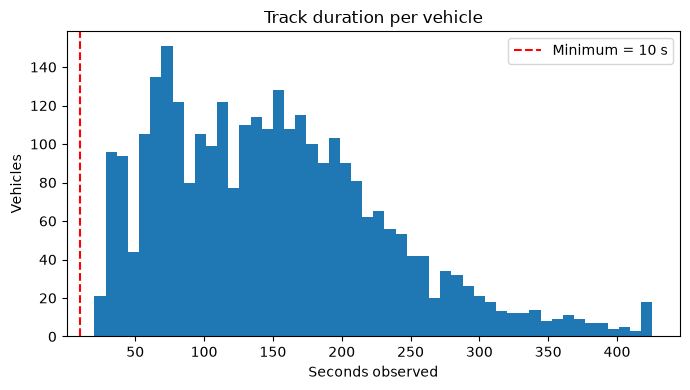

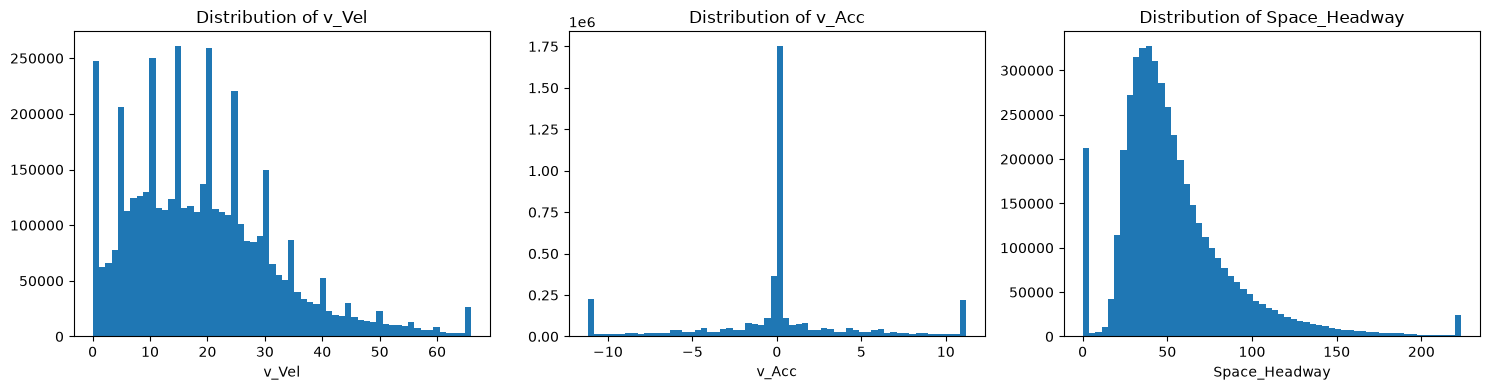


Share of acceleration values at the +/-11.2 ft/s^2 cap: 8.94%

Lane_ID counts (confirm which are mainline lanes):
Lane_ID
1    404588
2    830690
3    719832
4    880189
5    785454
6    791237
7    154397
Name: count, dtype: int64

Vehicle class counts (1 = motorcycle, 2 = auto, 3 = truck):
v_Class
1      19352
2    4377903
3     169132
Name: count, dtype: int64


In [4]:
# Cell 2: exploratory analysis (track lengths, distributions, lanes, classes)
track_len = df.groupby("Vehicle_ID").size()
dur = track_len / 10.0
print("Vehicles:", len(track_len))
print("Track duration (seconds):")
print(dur.describe().round(1))
REPORT["vehicles_total"] = int(len(track_len))
REPORT["dur_median_s"] = float(dur.median())
REPORT["dur_min_s"] = float(dur.min())
REPORT["dur_max_s"] = float(dur.max())
REPORT["veh_under_min"] = int((track_len < MIN_FRAMES).sum())

fig, ax = plt.subplots(1, 1, figsize=(7, 4))
ax.hist(dur.clip(upper=dur.quantile(0.995)), bins=50)
ax.axvline(MIN_FRAMES / 10, color="red", linestyle="--", label=f"Minimum = {MIN_FRAMES/10:.0f} s")
ax.set_title("Track duration per vehicle")
ax.set_xlabel("Seconds observed")
ax.set_ylabel("Vehicles")
ax.legend()
plt.tight_layout()
plt.savefig("figures/track_duration.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(axes, FEATURES):
    x = df[c].dropna()
    a.hist(x.clip(upper=x.quantile(0.995)), bins=60)
    a.set_title(f"Distribution of {c}")
    a.set_xlabel(c)
plt.tight_layout()
plt.savefig("figures/feature_distributions.png", dpi=150)
plt.show()

acc_clipped = float((df["v_Acc"].abs() >= CLIP_ACC).mean() * 100)
print(f"\nShare of acceleration values at the +/-11.2 ft/s^2 cap: {acc_clipped:.2f}%")
REPORT["acc_clipped_pct_all"] = acc_clipped
print("\nLane_ID counts (confirm which are mainline lanes):")
print(df["Lane_ID"].value_counts().sort_index())
print("\nVehicle class counts (1 = motorcycle, 2 = auto, 3 = truck):")
print(df["v_Class"].value_counts().sort_index())


In [5]:
# Cell 3: define the analysis cohort, then standardize
n0 = len(df)
keep_veh = track_len[track_len >= MIN_FRAMES].index
s1 = df[df["Vehicle_ID"].isin(keep_veh)]
s2 = s1[s1["Lane_ID"].isin(MAINLINE_LANES)]
s3 = s2[s2["Space_Headway"] > 0]
s3 = s3.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + ["Time_Headway"])

attr = pd.DataFrame({
    "Step": ["All rows", f"Vehicles tracked at least {MIN_FRAMES/10:.0f} s",
             "Mainline lanes only", "Has a lead vehicle (headway > 0), no missing values"],
    "Rows": [n0, len(s1), len(s2), len(s3)],
})
attr["% of all rows"] = (attr["Rows"] / n0 * 100).round(1)
print(attr.to_string(index=False))
REPORT["attrition"] = attr
REPORT["cohort_rows"] = len(s3)
REPORT["cohort_vehicles"] = int(s3["Vehicle_ID"].nunique())

sample = s3.sample(n=min(N_SAMPLE, len(s3)), random_state=SEED).reset_index(drop=True)
print("\nSample used for modelling:", len(sample))
REPORT["sample_rows"] = len(sample)
REPORT["acc_clipped_pct_sample"] = float((sample["v_Acc"].abs() >= CLIP_ACC).mean() * 100)

X_raw = sample[FEATURES].copy()
cap = X_raw["Space_Headway"].quantile(0.99)           # limit extreme headways at the 99th percentile
X_raw["Space_Headway"] = X_raw["Space_Headway"].clip(upper=cap)
REPORT["headway_cap_ft"] = float(cap)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)


                                               Step    Rows  % of all rows
                                           All rows 4566387          100.0
                     Vehicles tracked at least 10 s 4566387          100.0
                                Mainline lanes only 4411990           96.6
Has a lead vehicle (headway > 0), no missing values 4231188           92.7

Sample used for modelling: 100000


 k     inertia  silhouette
 2 197345.9355      0.3863
 3 156668.7673      0.3590
 4 124765.9645      0.3280
 5  98082.6037      0.3617
 6  87299.4421      0.3205


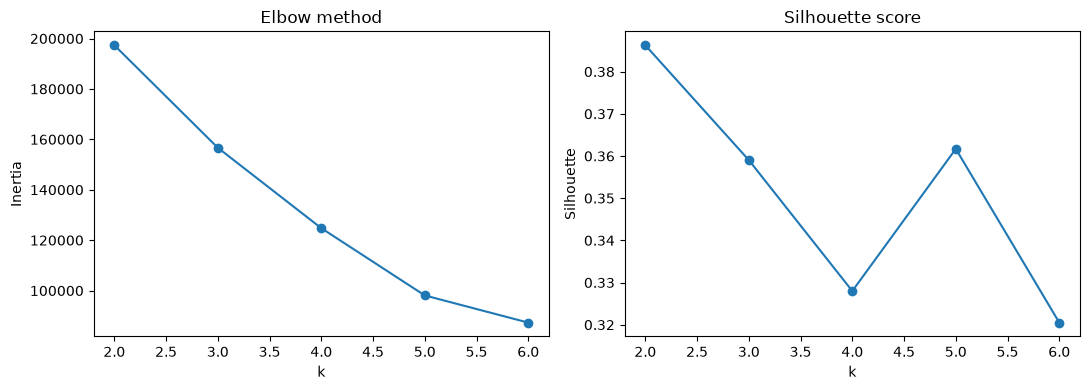

Chosen k (highest silhouette): 2
Stability over 10 random seeds: mean ARI = 0.9969, min ARI = 0.9899

Cluster profiles:
         Share_pct  Mean_speed_mph  Median_speed_mph  Mean_acc_ftps2  Mean_headway_ft  Median_headway_ft  Median_time_headway_s
Cluster                                                                                                                        
0            72.55            9.39              9.44           -0.11            42.38              40.82                   3.10
1            27.45           23.37             21.82            0.35            96.59              85.91                   2.69


In [6]:
# Cell 4: K-means model selection, final model, stability, cluster profiles
rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=5000, random_state=SEED)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
sel = pd.DataFrame(rows)
print(sel.round(4).to_string(index=False))
REPORT["k_table"] = sel

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sel["k"], sel["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(sel["k"], sel["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig("figures/kmeans_selection.png", dpi=150)
plt.show()

K = int(sel.loc[sel["silhouette"].idxmax(), "k"])
print("Chosen k (highest silhouette):", K)
REPORT["K"] = K

km_final = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
order = X_raw.groupby(km_final.labels_)["v_Vel"].mean().sort_values().index.tolist()
remap = {old: new for new, old in enumerate(order)}      # cluster 0 = slowest
labels = np.array([remap[l] for l in km_final.labels_])
centers = km_final.cluster_centers_[order]
sample["Cluster"] = labels

# stability across random seeds
aris = []
for s in range(1, 11):
    kk = KMeans(n_clusters=K, n_init=10, random_state=s).fit(X)
    aris.append(adjusted_rand_score(labels, kk.labels_))
print(f"Stability over 10 random seeds: mean ARI = {np.mean(aris):.4f}, min ARI = {np.min(aris):.4f}")
REPORT["ari_mean"] = float(np.mean(aris))
REPORT["ari_min"] = float(np.min(aris))

# cluster profiles in engineering units
tmp = sample.copy()
tmp["Speed_mph"] = tmp["v_Vel"] * FT_S_TO_MPH
tmp["TH_valid"] = tmp["Time_Headway"].where(tmp["Time_Headway"] < 9999)
prof = tmp.groupby("Cluster").agg(
    Share_pct=("v_Vel", lambda s: len(s) / len(tmp) * 100),
    Mean_speed_mph=("Speed_mph", "mean"),
    Median_speed_mph=("Speed_mph", "median"),
    Mean_acc_ftps2=("v_Acc", "mean"),
    Mean_headway_ft=("Space_Headway", "mean"),
    Median_headway_ft=("Space_Headway", "median"),
    Median_time_headway_s=("TH_valid", "median"),
).round(2)
print("\nCluster profiles:")
print(prof.to_string())
REPORT["profile"] = prof


Explained variance ratio: [0.5464 0.3333] | total: 0.8797
                  PC1     PC2
v_Vel          0.7048 -0.0795
v_Acc          0.0568  0.9968
Space_Headway  0.7071 -0.0008


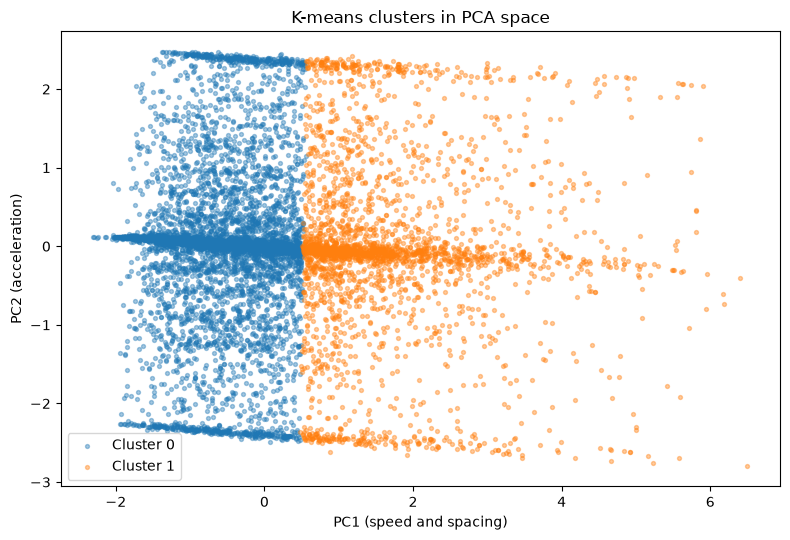

In [7]:
# Cell 5: PCA for visualization and interpretation
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
load = pd.DataFrame(pca.components_.T, columns=["PC1", "PC2"], index=FEATURES).round(4)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4), "| total:", round(pca.explained_variance_ratio_.sum(), 4))
print(load)
REPORT["pca_var"] = pca.explained_variance_ratio_
REPORT["pca_load"] = load

idx = np.random.RandomState(SEED).choice(len(X), size=min(10000, len(X)), replace=False)
plt.figure(figsize=(8, 5.5))
for c in range(K):
    m = labels[idx] == c
    plt.scatter(Z[idx][m, 0], Z[idx][m, 1], s=8, alpha=0.4, label=f"Cluster {c}")
plt.xlabel("PC1 (speed and spacing)")
plt.ylabel("PC2 (acceleration)")
plt.title("K-means clusters in PCA space")
plt.legend()
plt.tight_layout()
plt.savefig("figures/pca_clusters.png", dpi=150)
plt.show()


In [12]:

# Cell 6: anomaly detection (baseline + 3 methods) and agreement
def jaccard(a, b):
    return (a & b).sum() / max((a | b).sum(), 1)


flags = {}
flags["Baseline: 3-sigma rule"] = (np.abs(X) > 3).any(axis=1)

dist = np.linalg.norm(X - centers[labels], axis=1)
flags["K-means distance"] = dist > np.quantile(dist, 1 - FLAG_RATE)

# DBSCAN on a random subsample (the full 100,000 points needs too much memory), then every point is
# labeled noise if it is farther than eps from every dense "core" point
MIN_SAMPLES = 10
N_DB = 15000
sub = np.random.RandomState(SEED).choice(len(X), size=min(N_DB, len(X)), replace=False)
Xs = X[sub]
kd = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)[0][:, -1]
eps = float(np.quantile(kd, 1 - FLAG_RATE))
db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(Xs)
cores = Xs[db.core_sample_indices_]
d_core = NearestNeighbors(n_neighbors=1).fit(cores).kneighbors(X)[0][:, 0]
flags["DBSCAN noise"] = d_core > eps
n_db_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f"DBSCAN (fitted on {len(Xs)} points): eps = {eps:.3f}, min_samples = {MIN_SAMPLES}, clusters found = {n_db_clusters}, noise = {flags['DBSCAN noise'].mean()*100:.2f}%")
REPORT["dbscan_eps"] = eps
REPORT["dbscan_clusters"] = n_db_clusters
REPORT["dbscan_n"] = len(Xs)

iso = IsolationForest(n_estimators=200, contamination=FLAG_RATE, random_state=SEED, n_jobs=-1).fit(X)
flags["Isolation Forest"] = iso.predict(X) == -1

names = list(flags.keys())
rate = pd.Series({n: flags[n].mean() * 100 for n in names}).round(2)
print("\nFlag rate (%):")
print(rate.to_string())
REPORT["flag_rate"] = rate

jac = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        jac.loc[a, b] = jaccard(flags[a], flags[b])
print("\nOverlap between methods (Jaccard, 1 = identical):")
print(jac.round(3).to_string())
REPORT["jaccard"] = jac

ml = ["K-means distance", "DBSCAN noise", "Isolation Forest"]
votes = sum(flags[n].astype(int) for n in ml)
consensus = votes >= 2
print(f"\nFlagged by at least 2 of the 3 methods: {consensus.sum()} observations ({consensus.mean()*100:.2f}%)")
REPORT["consensus_n"] = int(consensus.sum())
REPORT["consensus_pct"] = float(consensus.mean() * 100)


DBSCAN (fitted on 15000 points): eps = 0.611, min_samples = 10, clusters found = 3, noise = 0.84%

Flag rate (%):
Baseline: 3-sigma rule    2.99
K-means distance          2.00
DBSCAN noise              0.84
Isolation Forest          2.00

Overlap between methods (Jaccard, 1 = identical):
                        Baseline: 3-sigma rule  K-means distance  DBSCAN noise  Isolation Forest
Baseline: 3-sigma rule                   1.000             0.516         0.226             0.457
K-means distance                         0.516             1.000         0.310             0.610
DBSCAN noise                             0.226             0.310         1.000             0.324
Isolation Forest                         0.457             0.610         0.324             1.000

Flagged by at least 2 of the 3 methods: 1634 observations (1.63%)


In [13]:
print("DBSCAN eps:", round(REPORT["dbscan_eps"], 3), "min_samples:", MIN_SAMPLES, "fitted on", REPORT["dbscan_n"], "points | clusters:", REPORT["dbscan_clusters"])

DBSCAN eps: 0.611 min_samples: 10 fitted on 15000 points | clusters: 3


In [14]:
# Cell 7: do anomalies survive after accounting for traffic state? (global vs within-cluster)
def within_state_flags(Xm, lab, rate_, seed):
    out = np.zeros(len(Xm), dtype=bool)
    for c in np.unique(lab):
        ii = np.where(lab == c)[0]
        m = IsolationForest(n_estimators=200, contamination=rate_, random_state=seed, n_jobs=-1).fit(Xm[ii])
        out[ii] = m.predict(Xm[ii]) == -1
    return out


glob = flags["Isolation Forest"]
state = within_state_flags(X, labels, FLAG_RATE, SEED)
both = glob & state
glob_only = glob & ~state
state_only = ~glob & state
ctx = pd.DataFrame({
    "Group": ["Flagged globally AND within own traffic state (unusual in any context)",
              "Flagged globally only (unusual overall, ordinary for its traffic state)",
              "Flagged within own state only"],
    "Observations": [int(both.sum()), int(glob_only.sum()), int(state_only.sum())],
})
ctx["% of globally flagged"] = (ctx["Observations"] / max(glob.sum(), 1) * 100).round(1).astype(str)
ctx.loc[2, "% of globally flagged"] = "n/a"
print(ctx.to_string(index=False))
REPORT["context"] = ctx

# who are the anomalies?
tmp["Flag_IF"] = glob
tmp["Flag_context"] = both
comp = tmp.groupby("Flag_IF").agg(
    Mean_speed_mph=("Speed_mph", "mean"),
    Mean_acc_ftps2=("v_Acc", "mean"),
    Mean_abs_acc=("v_Acc", lambda s: s.abs().mean()),
    Median_headway_ft=("Space_Headway", "median"),
    Median_time_headway_s=("TH_valid", "median"),
).round(2)
comp.index = ["Not flagged", "Flagged (Isolation Forest)"]
print("\nFlagged vs not flagged:")
print(comp.to_string())
REPORT["flag_compare"] = comp

lane_tab = (pd.crosstab(tmp["Lane_ID"], tmp["Flag_IF"], normalize="columns") * 100).round(1)
lane_tab.columns = ["Not flagged %", "Flagged %"]
class_tab = (pd.crosstab(tmp["v_Class"], tmp["Flag_IF"], normalize="columns") * 100).round(1)
class_tab.columns = ["Not flagged %", "Flagged %"]
print("\nLane mix:")
print(lane_tab.to_string())
print("\nVehicle class mix:")
print(class_tab.to_string())
REPORT["lane_tab"] = lane_tab
REPORT["class_tab"] = class_tab

# cluster mix of flagged observations
mix = (pd.crosstab(tmp["Cluster"], tmp["Flag_IF"], normalize="columns") * 100).round(1)
mix.columns = ["Not flagged %", "Flagged %"]
print("\nTraffic-state (cluster) mix:")
print(mix.to_string())
REPORT["cluster_mix"] = mix


                                                                  Group  Observations % of globally flagged
 Flagged globally AND within own traffic state (unusual in any context)           546                  27.3
Flagged globally only (unusual overall, ordinary for its traffic state)          1454                  72.7
                                          Flagged within own state only          1454                   n/a

Flagged vs not flagged:
                            Mean_speed_mph  Mean_acc_ftps2  Mean_abs_acc  Median_headway_ft  Median_time_headway_s
Not flagged                          12.76            0.02          2.72              47.49                   2.95
Flagged (Isolation Forest)           36.08           -0.00          7.28             163.55                   3.25

Lane mix:
         Not flagged %  Flagged %
Lane_ID                          
1                  7.5       77.8
2                 19.4        2.4
3                 16.6        5.2
4                

In [15]:
# Cell 8: sensitivity analysis
sens = []
for r in [0.01, 0.02, 0.05]:
    g = IsolationForest(n_estimators=200, contamination=r, random_state=SEED, n_jobs=-1).fit(X).predict(X) == -1
    s_ = within_state_flags(X, labels, r, SEED)
    sens.append({"Flag rate": f"{r*100:.0f}%",
                 "Flagged": int(g.sum()),
                 "% also flagged within own state": round((g & s_).sum() / max(g.sum(), 1) * 100, 1)})
sens = pd.DataFrame(sens)
print("Effect of the flag rate:")
print(sens.to_string(index=False))
REPORT["sens_rate"] = sens

jacs = []
for s in [1, 2, 3, 4, 5]:
    g = IsolationForest(n_estimators=200, contamination=FLAG_RATE, random_state=s, n_jobs=-1).fit(X).predict(X) == -1
    jacs.append(jaccard(glob, g))
print(f"\nIsolation Forest stability over 5 seeds: mean Jaccard = {np.mean(jacs):.3f}, min = {np.min(jacs):.3f}")
REPORT["if_jac_mean"] = float(np.mean(jacs))
REPORT["if_jac_min"] = float(np.min(jacs))

# remove observations at the acceleration cap and repeat
keep = (sample["v_Acc"].abs() < CLIP_ACC).values
X2_raw = X_raw[keep].copy()
X2 = StandardScaler().fit_transform(X2_raw)
km2 = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X2)
order2 = X2_raw.groupby(km2.labels_)["v_Vel"].mean().sort_values().index.tolist()
rm2 = {old: new for new, old in enumerate(order2)}
lab2 = np.array([rm2[l] for l in km2.labels_])
sil2 = silhouette_score(X2, km2.labels_, sample_size=5000, random_state=SEED)
ari2 = adjusted_rand_score(labels[keep], lab2)
g2 = IsolationForest(n_estimators=200, contamination=FLAG_RATE, random_state=SEED, n_jobs=-1).fit(X2).predict(X2) == -1
jac2 = jaccard(glob[keep], g2)
share_removed = (~keep).mean() * 100
print(f"\nWithout capped-acceleration rows ({share_removed:.2f}% removed): silhouette = {sil2:.4f}, "
      f"cluster agreement (ARI) = {ari2:.4f}, anomaly overlap (Jaccard) = {jac2:.3f}")
print("Cluster shares without capped rows (%):", (np.bincount(lab2) / len(lab2) * 100).round(2))
REPORT["nocap_removed_pct"] = float(share_removed)
REPORT["nocap_sil"] = float(sil2)
REPORT["nocap_ari"] = float(ari2)
REPORT["nocap_jac"] = float(jac2)
REPORT["nocap_shares"] = (np.bincount(lab2) / len(lab2) * 100).round(2)


Effect of the flag rate:
Flag rate  Flagged  % also flagged within own state
       1%     1000                             26.5
       2%     2000                             27.3
       5%     5000                             31.6

Isolation Forest stability over 5 seeds: mean Jaccard = 0.837, min = 0.797

Without capped-acceleration rows (8.81% removed): silhouette = 0.3837, cluster agreement (ARI) = 0.9246, anomaly overlap (Jaccard) = 0.674
Cluster shares without capped rows (%): [71.69 28.31]


In [16]:
# Cell 9: print every number needed for the report 
print("=" * 70)
print("REPORT NUMBERS (copy everything from here to the end)")
print("=" * 70)
print("Rows total:", REPORT["rows_total"], "| vehicles:", REPORT["vehicles_total"])
print("Track duration s: median", round(REPORT["dur_median_s"], 1), "min", REPORT["dur_min_s"], "max", REPORT["dur_max_s"],
      "| vehicles under minimum:", REPORT["veh_under_min"])
print("Acceleration at cap (all rows %):", round(REPORT["acc_clipped_pct_all"], 2), "| in sample %:", round(REPORT["acc_clipped_pct_sample"], 2))
print("\nAttrition:\n", REPORT["attrition"].to_string(index=False))
print("Cohort vehicles:", REPORT["cohort_vehicles"], "| sample rows:", REPORT["sample_rows"], "| headway cap ft:", round(REPORT["headway_cap_ft"], 1))
print("\nk table:\n", REPORT["k_table"].round(4).to_string(index=False))
print("Chosen k:", REPORT["K"], "| ARI mean/min:", round(REPORT["ari_mean"], 4), round(REPORT["ari_min"], 4))
print("\nProfiles:\n", REPORT["profile"].to_string())
print("\nPCA variance:", np.round(REPORT["pca_var"], 4), "\n", REPORT["pca_load"].to_string())
print("\nFlag rates %:\n", REPORT["flag_rate"].to_string())
print("DBSCAN eps:", round(REPORT["dbscan_eps"], 3), "clusters:", REPORT["dbscan_clusters"])
print("\nJaccard:\n", REPORT["jaccard"].round(3).to_string())
print("Consensus (>=2 of 3):", REPORT["consensus_n"], f"({REPORT['consensus_pct']:.2f}%)")
print("\nContext table:\n", REPORT["context"].to_string(index=False))
print("\nFlagged vs not:\n", REPORT["flag_compare"].to_string())
print("\nLane mix:\n", REPORT["lane_tab"].to_string())
print("\nClass mix:\n", REPORT["class_tab"].to_string())
print("\nCluster mix:\n", REPORT["cluster_mix"].to_string())
print("\nSensitivity to flag rate:\n", REPORT["sens_rate"].to_string(index=False))
print("IF seed stability Jaccard mean/min:", round(REPORT["if_jac_mean"], 3), round(REPORT["if_jac_min"], 3))
print("No-cap check: removed %", round(REPORT["nocap_removed_pct"], 2), "| silhouette", round(REPORT["nocap_sil"], 4),
      "| ARI", round(REPORT["nocap_ari"], 4), "| Jaccard", round(REPORT["nocap_jac"], 3), "| shares", REPORT["nocap_shares"])


REPORT NUMBERS (copy everything from here to the end)
Rows total: 4566387 | vehicles: 3001
Track duration s: median 144.4 min 20.4 max 525.6 | vehicles under minimum: 0
Acceleration at cap (all rows %): 8.94 | in sample %: 8.81

Attrition:
                                                Step    Rows  % of all rows
                                           All rows 4566387          100.0
                     Vehicles tracked at least 10 s 4566387          100.0
                                Mainline lanes only 4411990           96.6
Has a lead vehicle (headway > 0), no missing values 4231188           92.7
Cohort vehicles: 2998 | sample rows: 100000 | headway cap ft: 186.8

k table:
  k     inertia  silhouette
 2 197345.9355      0.3863
 3 156668.7673      0.3590
 4 124765.9645      0.3280
 5  98082.6037      0.3617
 6  87299.4421      0.3205
Chosen k: 2 | ARI mean/min: 0.9969 0.9899

Profiles:
          Share_pct  Mean_speed_mph  Median_speed_mph  Mean_acc_ftps2  Mean_headway_ft  Me